# Zadanie 1, Część II: osadzenia tekstów i klasyfikacja

Notebook realizuje Część II na zbiorze zaanotowanym w Części I (443 dokumenty, klasy `medical_doc`, `official_doc`, `other`).
Część dotycząca dokumentów pisanych odręcznie została pominięta (pyt. 5 z części o osadzeniach i pyt. 7 z części o klasyfikacji, pkt 3b).

Ciężkie obliczenia (lematyzacja, osadzenia, walidacja krzyżowa) są cache'owane w ignorowanym przez Git katalogu `data/part2/`.
Interaktywne wykresy zapisywane są dodatkowo jako HTML w `reports/figures/`.

In [1]:
import os

os.environ.update({"HF_HUB_DISABLE_PROGRESS_BARS": "1", "TRANSFORMERS_VERBOSITY": "error", "TQDM_DISABLE": "1"})

import pickle
import re
import unicodedata
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

from src.annotation_common import LABELS
from src.part2 import analysis, classify
from src.part2.data import CACHE_DIR, FIGURES_DIR, load_corpus, tokenize
from src.part2.embeddings import (
    ENCODERS,
    EMBEDDINGS_DIR,
    STATIC_MODELS,
    compute_encoder_embeddings,
    compute_static_embeddings,
    encode_texts,
    load_encoder,
    load_static_model,
    static_document_vectors,
)
from src.part2.lemmatize import lemmatize_corpus

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 0. Dane

Strony z pliku `corpus_medical_official_docs.parquet` łączone są w dokumenty (jak w Części I), a etykiety pochodzą z `annotations/annotated_documents.csv`.

Tekst z OCR zawiera dużo szumu układu strony: tabele markdown (`| :--- |`), `<br>`, `**` oraz bardzo długie ciągi kropek z pól formularzy.
Trzy największe dokumenty (264–392 tys. znaków) składały się w ~98% z kropek i znaków układu strony. Po usunięciu tego szumu maksymalna długość spada do ~12 tys. znaków.

Dokumenty to wypełnione formularze, więc grupujemy je w szablony aglomeracyjnie (TF-IDF na początku dokumentu bez cyfr, próg odległości kosinusowej 0,5).
Szablony posłużą do uczciwej ewaluacji (leave-template-out), bo dokumenty z tego samego formularza są niemal identyczne.

In [2]:
corpus = load_corpus()
lemmas = lemmatize_corpus(corpus)
y = corpus["label"].to_numpy()
groups = corpus["template_id"].to_numpy()

display(corpus[["character_count", "clean_character_count", "word_count", "page_count"]].describe().round(1))
templates = corpus.groupby("template")["label"].value_counts().unstack(fill_value=0)
templates["razem"] = templates.sum(axis=1)
display(templates)
print(f"Szablonów: {corpus['template_id'].nunique()}, mieszanych etykiet: {(templates[list(LABELS)].gt(0).sum(axis=1) > 1).sum()}")

,character_count,clean_character_count,word_count,page_count
count,443.0,443.0,443.0,443.0
mean,10506.4,4622.4,511.2,2.5
std,32044.6,2257.4,236.6,0.9
min,2215.0,2049.0,243.0,2.0
25%,3063.5,3032.0,357.5,2.0
50%,4637.0,3764.0,424.0,2.0
75%,6668.5,6339.5,653.5,3.0
max,392106.0,12176.0,1365.0,5.0


label,medical_doc,official_doc,other,razem
template,,,,
T00 zawartej zakładem pieczęć ośrodka ks,18,0,0,18
T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,15,0,0,15
T02 zawartej zakładem pieczęć ośrodka ks,10,0,0,10
T03 OL-4 ol sprzeciw wobec orzeczenia lekarza,0,18,0,18
T04 oddział biała podlaska akt opinia,22,0,0,22
T05 PR-4 pr wniosek rehabilitację leczniczą ramach,0,28,0,28
T06 POLTAX poltax pola jasne wypełnia podatnik,0,23,0,23
T07 zaświadczenie pomocy minimis data wydania,0,3,0,3
T08 OL-10 ol wywiad zawodowy pieczęć zakładu,0,17,0,17


Szablonów: 24, mieszanych etykiet: 1


Wszystkie szablony poza jednym są jednorodne co do etykiety.
Wyjątkiem jest ankieta satysfakcji (T13): 14 × `medical_doc` i 1 × `other`.
Ten jedyny dokument `other` pochodzi z pilotażu (runda 1, wytyczne v1), w którym obaj anotatorzy zgodnie wybrali `other`.
Wytyczne v2 wprost każą oznaczać ankiety jako `medical_doc`, więc jest to szum w etykietach pozostały po pierwszej iteracji.

Klasa `other` to w praktyce jeden szablon (lista kontrolna ergonomii stanowiska komputerowego, 27 dokumentów).

## 1. Osadzenia tekstów: modele statyczne a kontekstowe

### 1.1 Modele i co przekazujemy do modelu

| Model | Typ | Trenowany na | Wymiar | Uwagi |
|---|---|---|---|---|
| `clarin-pl/word2vec-kgr10` (CBOW) | statyczny, Word2Vec | lematach (KGR10, 4 mld słów) | 300 | brak form typu „jest”, „lekarza” ma rangę ~1 mln (szum) |
| `clarin-pl/fastText-kgr10` (`plain.skipgram.dim100`) | statyczny, fastText | formach | 100 | n-gramy znakowe, wektor dla każdego słowa (także OOV) |
| `sdadas/mmlw-roberta-base` | enkoder zdań | – | 768 | okno 512 tokenów, prefiks `zapytanie: ` (wymóg karty modelu) |
| `BAAI/bge-m3` | enkoder zdań | – | 1024 | wielojęzyczny, kontekst do 8192 tokenów, bez prefiksu |

W modelach statycznych wektor dokumentu to średnia wektorów słów (`mean`) oraz średnia ważona SIF (`a/(a+p(w))`, usunięcie pierwszej składowej głównej; Arora i in., 2017).
Każdy wariant liczony na formach i na lematach (spaCy `pl_core_news_lg`).

Enkodery mają limit 512 tokenów, a mediana dokumentu po czyszczeniu to 867 tokenów MMLW i 97% tekstów przekracza 512.
Porównujemy trzy strategie:
* `head`: tylko pierwsze okno 500 tokenów (to, co daje zwykłe obcięcie),
* `chunks`: dokument dzielony na kolejne okna po 500 tokenów, każde osadzane osobno, potem średnia znormalizowanych wektorów,
* `long` (tylko bge-m3): jedno przejście przez cały dokument (do 8192 tokenów).

Dodatkowo, jako eksperyment kontrolny do pytań o lematyzację, MMLW zakodowano też na tekście zlematyzowanym (`mmlw-lemmas`).

In [3]:
static = compute_static_embeddings(lemmas)
encoded = compute_encoder_embeddings(corpus, lemmas)

coverage = pd.DataFrame(
    [
        {
            "model": key.split("_")[0],
            "wejście": key.split("_")[1],
            "pokrycie słownika": round(float(value["coverage"].mean()), 3),
        }
        for key, value in static.items()
        if key.endswith("_mean")
    ]
)
display(coverage)
windows = np.load(EMBEDDINGS_DIR / "mmlw_window_counts.npy")
print(f"Okien 500 tokenów na dokument (MMLW): mediana {np.median(windows):.0f}, średnia {windows.mean():.2f}, max {windows.max()}")

,model,wejście,pokrycie słownika
0,w2v,forms,0.725
1,w2v,lemmas,0.939
2,fasttext,forms,0.995
3,fasttext,lemmas,0.976


Okien 500 tokenów na dokument (MMLW): mediana 2, średnia 2.80, max 6


Pokrycie słownika potwierdza, że Word2Vec KGR10 był trenowany na lematach: dla form fleksyjnych wektor istnieje tylko dla 72,5% słów, a po lematyzacji dla 93,9%.
fastText (trenowany na formach) ma niemal pełne pokrycie dla form i nieco niższe dla lematów; a nawet dla słów spoza słownika buduje wektor z n-gramów znakowych.

In [4]:
tfidf_forms_matrix = TfidfVectorizer(token_pattern=r"\S+", min_df=2, sublinear_tf=True).fit_transform(
    [" ".join(tokens) for tokens in lemmas["forms"]]
)
tfidf_svd = TruncatedSVD(100, random_state=42).fit_transform(tfidf_forms_matrix)

spaces = {
    "TF-IDF (formy, SVD-100)": tfidf_svd,
    "Word2Vec – lematy, średnia": static["w2v_lemmas_mean"]["vectors"],
    "Word2Vec – formy, średnia": static["w2v_forms_mean"]["vectors"],
    "fastText – formy, średnia": static["fasttext_forms_mean"]["vectors"],
    "fastText – formy, SIF": static["fasttext_forms_sif"]["vectors"],
    "MMLW – head": encoded["mmlw_head"],
    "MMLW – chunks": encoded["mmlw_chunks"],
    "bge-m3 – head": encoded["bge-m3_head"],
    "bge-m3 – chunks": encoded["bge-m3_chunks"],
    "bge-m3 – long": encoded["bge-m3_long"],
}

### 1.2 Wizualizacja (UMAP i t-SNE)

Wykresy są interaktywne: po najechaniu na punkt widać szablon, etykietę, nazwę pliku, liczbę słów i fragment tekstu. Krzyżyk oznacza dokument sporny z Części I.
Każdy wykres zapisano też jako osobny plik HTML w `reports/figures/`.

In [5]:
projection_cache = CACHE_DIR / "projections.pkl"
projections = pickle.loads(projection_cache.read_bytes()) if projection_cache.exists() else {}
for name, vectors in spaces.items():
    for method in ("umap", "tsne"):
        if (name, method) not in projections:
            projections[(name, method)] = analysis.project(vectors, method)
projection_cache.write_bytes(pickle.dumps(projections))


def file_stem(name: str, method: str) -> str:
    ascii_name = unicodedata.normalize("NFKD", name.replace("ł", "l")).encode("ascii", "ignore").decode()
    return f"{method}_" + "_".join(re.findall(r"[a-z0-9]+", ascii_name.lower()))


for name in ["Word2Vec – lematy, średnia", "fastText – formy, średnia", "MMLW – chunks", "bge-m3 – long"]:
    analysis.interactive_scatter(projections[(name, "umap")], corpus, f"UMAP: {name}", file_stem(name, "umap")).show()
for name in spaces:
    for method in ("umap", "tsne"):
        analysis.interactive_scatter(projections[(name, method)], corpus, f"{method.upper()}: {name}", file_stem(name, method))

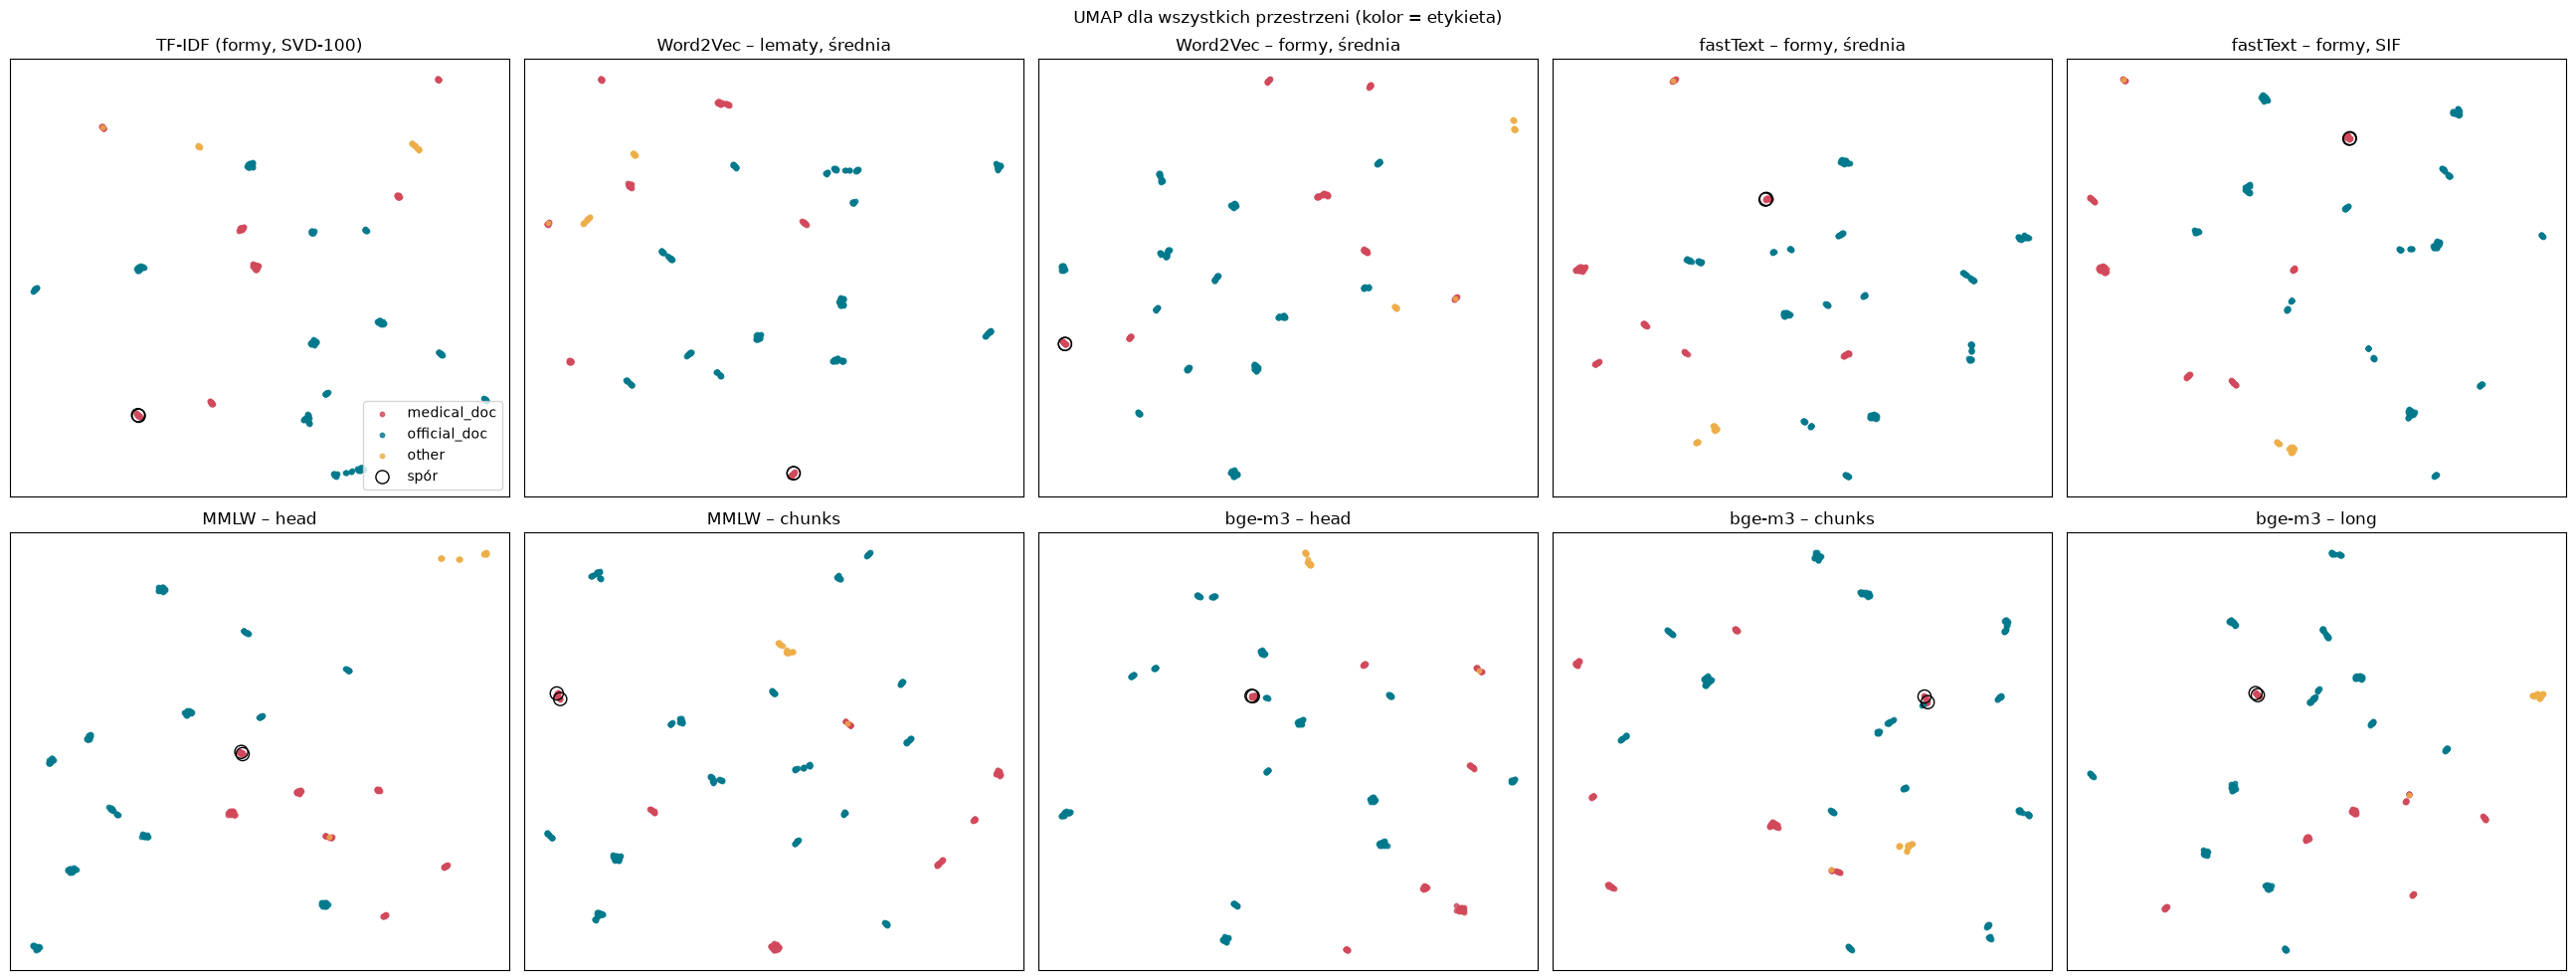

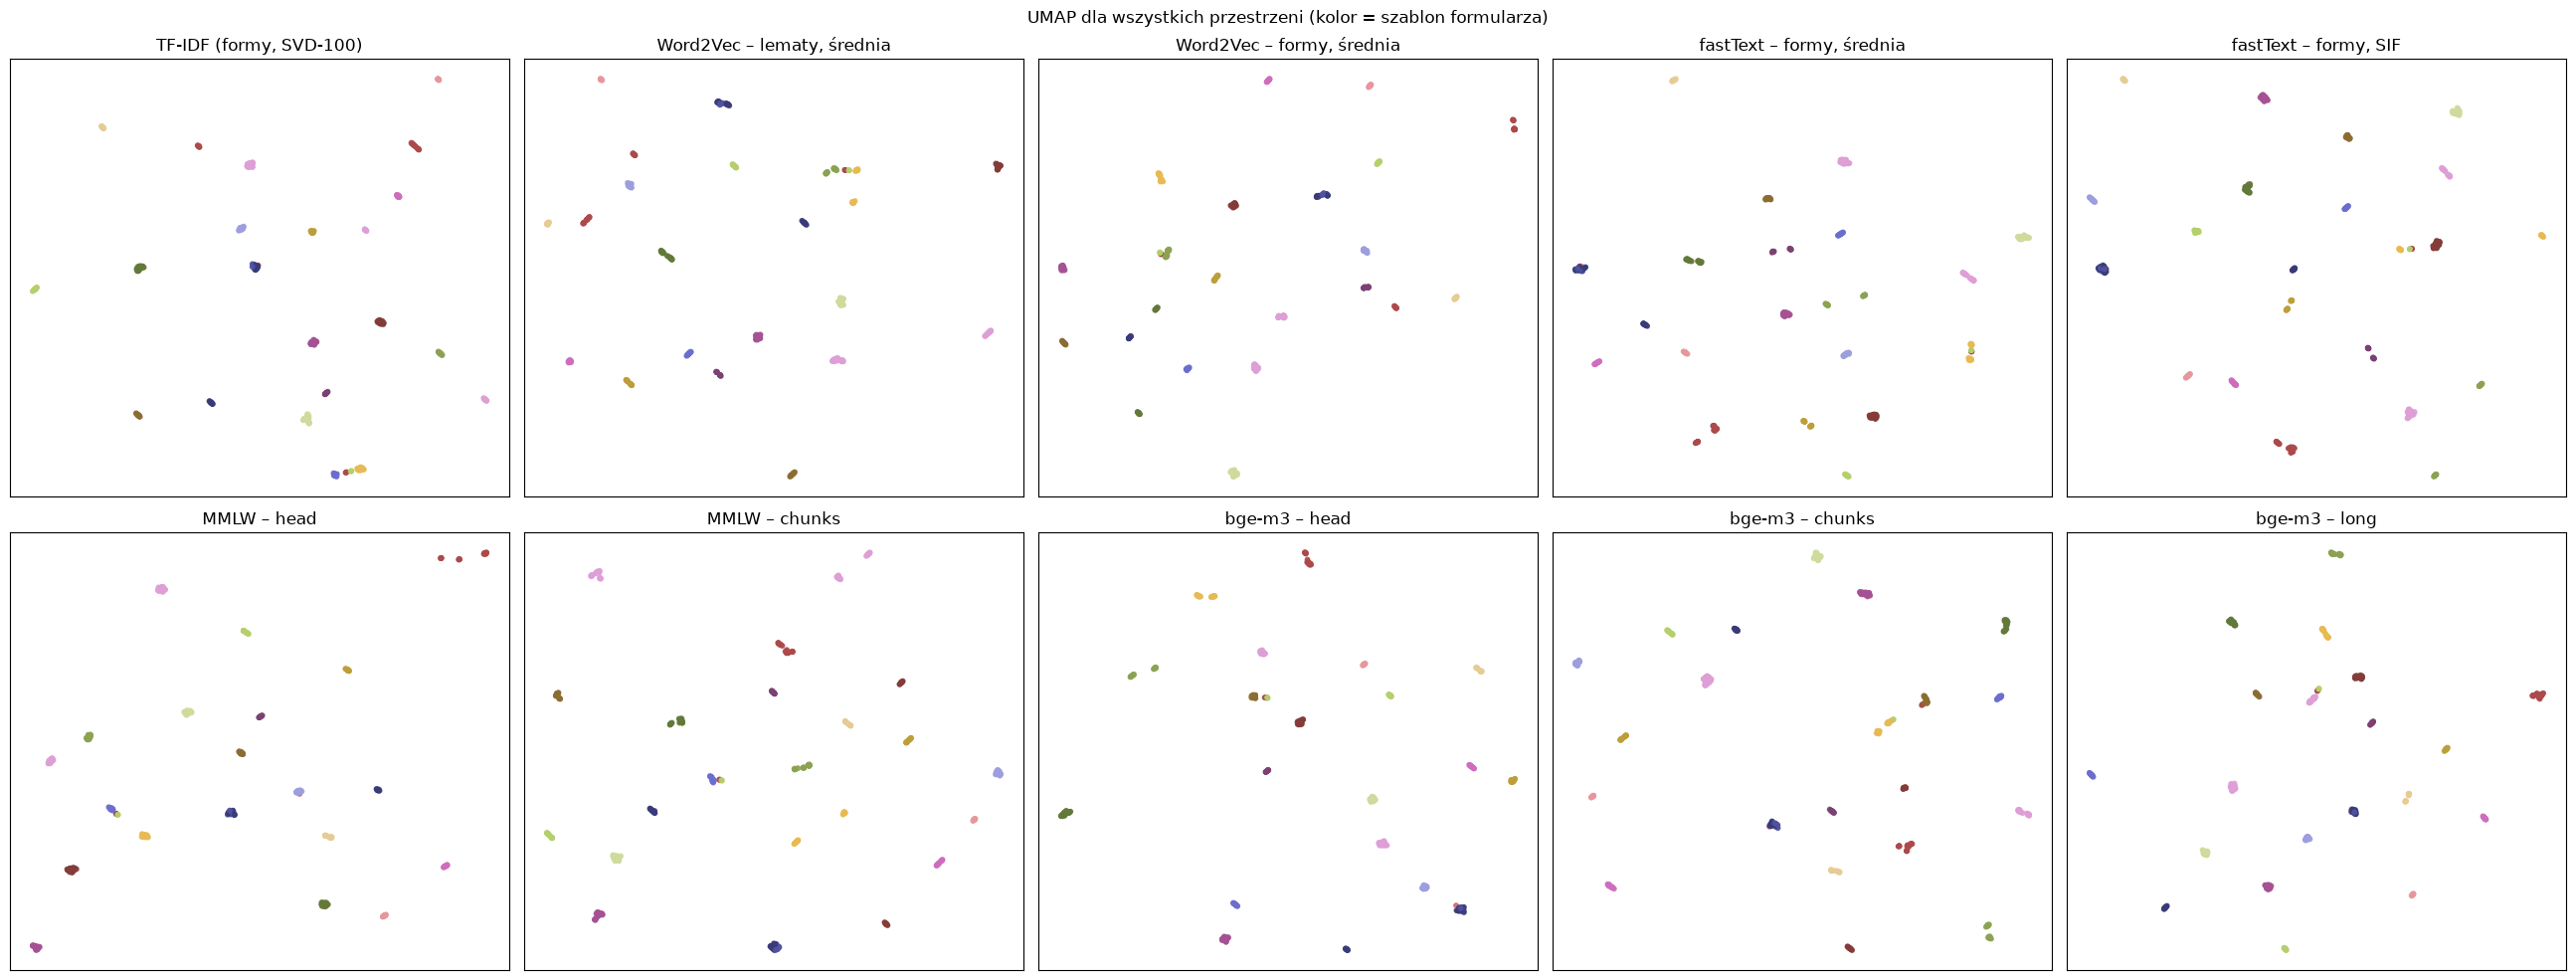

In [6]:
figure, axes = plt.subplots(2, 5, figsize=(26, 10))
for axis, name in zip(axes.flat, spaces):
    points = projections[(name, "umap")]
    for label, color in analysis.LABEL_COLORS.items():
        mask = y == label
        axis.scatter(points[mask, 0], points[mask, 1], s=10, c=color, label=label, alpha=0.8)
    disputed = corpus["had_disagreement"].to_numpy()
    axis.scatter(points[disputed, 0], points[disputed, 1], s=90, facecolors="none", edgecolors="black", label="spór")
    axis.set_title(name)
    axis.set_xticks([])
    axis.set_yticks([])
axes.flat[0].legend(loc="best")
figure.suptitle("UMAP dla wszystkich przestrzeni (kolor = etykieta)")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "umap_overview.png", dpi=110)
plt.show()

figure, axes = plt.subplots(2, 5, figsize=(26, 10))
for axis, name in zip(axes.flat, spaces):
    points = projections[(name, "umap")]
    axis.scatter(points[:, 0], points[:, 1], s=10, c=groups, cmap="tab20b", alpha=0.85)
    axis.set_title(name)
    axis.set_xticks([])
    axis.set_yticks([])
figure.suptitle("UMAP dla wszystkich przestrzeni (kolor = szablon formularza)")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "umap_overview_templates.png", dpi=110)
plt.show()

### 1.3 Ilościowa ocena separacji klas

* `silhouette_label` / `silhouette_template`: współczynnik sylwetki (kosinus) w pełnej przestrzeni względem etykiety / szablonu,
* `knn_acc`: trafność głosowania 5 najbliższych sąsiadów (leave-one-out),
* `knn_acc_cross_template`: to samo, ale sąsiedzi z tego samego szablonu są wykluczeni: czy model umieszcza blisko siebie różne formularze tej samej klasy?
* `clusters`, `ari_vs_*`: HDBSCAN bez nadzoru i zgodność (ARI) skupień z etykietami i szablonami.

In [7]:
separation = pd.DataFrame(
    {
        name: {
            **analysis.separation_metrics(vectors, y, groups),
            **analysis.cluster_agreement(vectors, corpus),
        }
        for name, vectors in spaces.items()
    }
).T.round(3)
display(separation)

,silhouette_label,silhouette_template,knn_acc,knn_acc_cross_template,clusters,noise_share,ari_vs_label,ari_vs_template
"TF-IDF (formy, SVD-100)",0.171,0.855,0.998,0.756,23.0,0.000,0.091,0.940
"Word2Vec – lematy, średnia",0.298,0.918,0.998,0.752,22.0,0.000,0.094,0.956
"Word2Vec – formy, średnia",0.256,0.914,0.998,0.777,23.0,0.000,0.093,0.949
"fastText – formy, średnia",0.347,0.913,0.998,0.704,22.0,0.005,0.094,0.954
"fastText – formy, SIF",0.201,0.885,0.998,0.731,22.0,0.000,0.095,0.959
MMLW – head,0.223,0.769,0.998,0.711,24.0,0.011,0.092,0.944
MMLW – chunks,0.258,0.708,0.998,0.596,26.0,0.034,0.084,0.891
bge-m3 – head,0.183,0.747,0.998,0.783,24.0,0.016,0.090,0.935
bge-m3 – chunks,0.218,0.748,0.991,0.598,21.0,0.027,0.093,0.948
bge-m3 – long,0.193,0.770,0.998,0.738,22.0,0.002,0.097,0.969


### 1.4 Pyt. 1: dokumenty podobne dla modelu, ale z różnych klas

Dla każdego modelu najbardziej podobne pary dokumentów o różnych etykietach (jedna para na parę szablonów).

In [8]:
for name in ["TF-IDF (formy, SVD-100)", "Word2Vec – lematy, średnia", "fastText – formy, średnia", "MMLW – chunks", "bge-m3 – long"]:
    display(Markdown(f"**{name}**"))
    display(analysis.cross_label_neighbours(spaces[name], corpus, top=5))

**TF-IDF (formy, SVD-100)**

,cosine,doc_a,label_a,doc_b,label_b
0,1.000,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,other,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,medical_doc
1,0.525,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc,T05 PR-4 pr wniosek rehabilitację leczniczą ramach,official_doc
2,0.447,T10 OL-9A ol informacja miejscach leczenia instrukcja,medical_doc,T20 OL-13 ol wniosk wydanie orzeczenia sprawie,official_doc
3,0.424,T03 OL-4 ol sprzeciw wobec orzeczenia lekarza,official_doc,T10 OL-9A ol informacja miejscach leczenia instrukcja,medical_doc
4,0.375,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc,T09 OL-2 ol wniosek pracodawcy kontrolę zaświadczenia,official_doc


**Word2Vec – lematy, średnia**

,cosine,doc_a,label_a,doc_b,label_b
0,1.000,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,other,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,medical_doc
1,0.954,T05 PR-4 pr wniosek rehabilitację leczniczą ramach,official_doc,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc
2,0.944,T20 OL-13 ol wniosk wydanie orzeczenia sprawie,official_doc,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc
3,0.942,T05 PR-4 pr wniosek rehabilitację leczniczą ramach,official_doc,T10 OL-9A ol informacja miejscach leczenia instrukcja,medical_doc
4,0.936,T09 OL-2 ol wniosek pracodawcy kontrolę zaświadczenia,official_doc,T10 OL-9A ol informacja miejscach leczenia instrukcja,medical_doc


**fastText – formy, średnia**

,cosine,doc_a,label_a,doc_b,label_b
0,1.000,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,other,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,medical_doc
1,0.990,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc,T20 OL-13 ol wniosk wydanie orzeczenia sprawie,official_doc
2,0.989,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc,T05 PR-4 pr wniosek rehabilitację leczniczą ramach,official_doc
3,0.985,T05 PR-4 pr wniosek rehabilitację leczniczą ramach,official_doc,T10 OL-9A ol informacja miejscach leczenia instrukcja,medical_doc
4,0.980,T09 OL-2 ol wniosek pracodawcy kontrolę zaświadczenia,official_doc,T10 OL-9A ol informacja miejscach leczenia instrukcja,medical_doc


**MMLW – chunks**

,cosine,doc_a,label_a,doc_b,label_b
0,0.991,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,other,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,medical_doc
1,0.989,T10 OL-9A ol informacja miejscach leczenia instrukcja,medical_doc,T03 OL-4 ol sprzeciw wobec orzeczenia lekarza,official_doc
2,0.982,T09 OL-2 ol wniosek pracodawcy kontrolę zaświadczenia,official_doc,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc
3,0.981,T05 PR-4 pr wniosek rehabilitację leczniczą ramach,official_doc,T10 OL-9A ol informacja miejscach leczenia instrukcja,medical_doc
4,0.977,T08 OL-10 ol wywiad zawodowy pieczęć zakładu,official_doc,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc


**bge-m3 – long**

,cosine,doc_a,label_a,doc_b,label_b
0,0.996,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,other,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,medical_doc
1,0.817,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc,T09 OL-2 ol wniosek pracodawcy kontrolę zaświadczenia,official_doc
2,0.816,T03 OL-4 ol sprzeciw wobec orzeczenia lekarza,official_doc,T10 OL-9A ol informacja miejscach leczenia instrukcja,medical_doc
3,0.807,T08 OL-10 ol wywiad zawodowy pieczęć zakładu,official_doc,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc
4,0.805,T09 OL-2 ol wniosek pracodawcy kontrolę zaświadczenia,official_doc,T10 OL-9A ol informacja miejscach leczenia instrukcja,medical_doc


### 1.5 Pyt. 2: semantycznie podobne, ale różne słowa

Najpierw prosty test na parach zdań: pary zdań o tym samym sensie wyrażonym innymi słowami oraz pary kontrolne z dużym wspólnym słownictwem, ale innym sensem.

In [9]:
probe_pairs = [
    ("parafraza", "Zaświadczenie lekarskie o stanie zdrowia pacjenta", "Opinia medyczna opisująca kondycję chorego"),
    ("parafraza", "Wniosek o przyznanie renty z tytułu niezdolności do pracy", "Prośba o świadczenie dla osoby, która nie może pracować"),
    ("parafraza", "Zeznanie podatkowe za ubiegły rok", "Rozliczenie z fiskusem za poprzednie dwanaście miesięcy"),
    ("parafraza", "Pacjent skarży się na ból w klatce piersiowej", "Chory zgłasza dolegliwości w okolicy serca"),
    ("parafraza", "Pracodawca wnioskuje o kontrolę zwolnienia lekarskiego", "Firma prosi o sprawdzenie L4 pracownika"),
    ("kontrola", "Lekarz wystawił zaświadczenie o stanie zdrowia", "Urząd wystawił zaświadczenie o stanie majątku"),
    ("kontrola", "Wniosek o rehabilitację leczniczą", "Wniosek o zwrot nadpłaconego podatku"),
    ("kontrola", "Pacjent nie zgłasza dolegliwości bólowych", "Pacjent zgłasza silne dolegliwości bólowe"),
]
probe_texts = [text for _, left, right in probe_pairs for text in (left, right)]

import spacy

nlp = spacy.load("pl_core_news_lg", disable=["parser", "ner"])
probe_docs = list(nlp.pipe(probe_texts))
probe_forms = [[token.text.lower() for token in doc if token.is_alpha] for doc in probe_docs]
probe_lemmas = [[token.lemma_.lower() for token in doc if token.is_alpha] for doc in probe_docs]

probe_vectors = {}
for model in STATIC_MODELS.values():
    keyed_vectors = load_static_model(model)
    column = probe_lemmas if model.trained_on == "lematy" else probe_forms
    probe_vectors[f"{model.name} ({model.trained_on})"] = static_document_vectors(
        keyed_vectors, column, use_subwords=model.kind == "fasttext"
    )[0]
    if model.kind == "fasttext":
        fasttext_vectors = keyed_vectors
    else:
        del keyed_vectors

encoder_models = {name: load_encoder(encoder) for name, encoder in ENCODERS.items()}
for name, model in encoder_models.items():
    probe_vectors[name] = encode_texts(name, probe_texts, model)

tfidf_probe = TfidfVectorizer(token_pattern=r"\S+").fit([" ".join(t) for t in lemmas["lemmas"]])
probe_vectors["TF-IDF (lematy)"] = tfidf_probe.transform([" ".join(t) for t in probe_lemmas]).toarray()

rows = []
for index, (kind, left, right) in enumerate(probe_pairs):
    row = {"typ": kind, "zdanie A": left, "zdanie B": right}
    for name, vectors in probe_vectors.items():
        a, b = normalize(vectors[2 * index : 2 * index + 2] + 1e-12)
        row[name] = round(float(a @ b), 3)
    rows.append(row)
probe_table = pd.DataFrame(rows)
display(probe_table)
display(probe_table.groupby("typ")[list(probe_vectors)].mean().round(3))

W1017 19:23:52.536000 88961 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


,typ,zdanie A,zdanie B,w2v (lematy),fasttext (formy),mmlw,bge-m3,TF-IDF (lematy)
0,parafraza,Zaświadczenie lekarskie o stanie zdrowia pacjenta,Opinia medyczna opisująca kondycję chorego,0.694,0.740,0.913,0.698,0.000
1,parafraza,Wniosek o przyznanie renty z tytułu niezdolności do pracy,"Prośba o świadczenie dla osoby, która nie może pracować",0.574,0.809,0.920,0.797,0.000
2,parafraza,Zeznanie podatkowe za ubiegły rok,Rozliczenie z fiskusem za poprzednie dwanaście miesięcy,0.703,0.851,0.925,0.730,0.100
3,parafraza,Pacjent skarży się na ból w klatce piersiowej,Chory zgłasza dolegliwości w okolicy serca,0.584,0.882,0.951,0.751,0.075
4,parafraza,Pracodawca wnioskuje o kontrolę zwolnienia lekarskiego,Firma prosi o sprawdzenie L4 pracownika,0.509,0.804,0.907,0.649,0.000
5,kontrola,Lekarz wystawił zaświadczenie o stanie zdrowia,Urząd wystawił zaświadczenie o stanie majątku,0.729,0.903,0.908,0.727,0.740
6,kontrola,Wniosek o rehabilitację leczniczą,Wniosek o zwrot nadpłaconego podatku,0.491,0.728,0.871,0.626,0.222
7,kontrola,Pacjent nie zgłasza dolegliwości bólowych,Pacjent zgłasza silne dolegliwości bólowe,0.901,0.940,0.932,0.719,0.992


,w2v (lematy),fasttext (formy),mmlw,bge-m3,TF-IDF (lematy)
typ,,,,,
kontrola,0.707,0.857,0.904,0.691,0.651
parafraza,0.613,0.817,0.923,0.725,0.035


Potem to samo w korpusie: najmniej podobne pary różnych szablonów tej samej klasy (centroidy szablonów).
Wysoka wartość oznacza, że model rozpoznaje wspólny sens mimo innego formularza i słownictwa.

In [10]:
far_pairs = {}
for name in ["TF-IDF (formy, SVD-100)", "Word2Vec – lematy, średnia", "fastText – formy, średnia", "MMLW – chunks", "bge-m3 – long"]:
    table = analysis.same_label_far_pairs(spaces[name], corpus, "medical_doc", top=3)
    far_pairs[name] = table
    display(Markdown(f"**{name}**: najdalsze szablony `medical_doc`"))
    display(table)

**TF-IDF (formy, SVD-100)**: najdalsze szablony `medical_doc`

,cosine,template_a,template_b
30,0.011,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,T17 ocena kliniczna dniu przyjęcia wywiad
33,0.013,T17 ocena kliniczna dniu przyjęcia wywiad,T18 pieczęćka świadczeniodawcy nfz karta oceny
34,0.024,T17 ocena kliniczna dniu przyjęcia wywiad,T21 formularz oceny funkcjonowania osób zaburzeniami


**Word2Vec – lematy, średnia**: najdalsze szablony `medical_doc`

,cosine,template_a,template_b
30,0.438,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,T17 ocena kliniczna dniu przyjęcia wywiad
27,0.542,T10 OL-9A ol informacja miejscach leczenia instrukcja,T17 ocena kliniczna dniu przyjęcia wywiad
4,0.546,T00 zawartej zakładem pieczęć ośrodka ks,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź


**fastText – formy, średnia**: najdalsze szablony `medical_doc`

,cosine,template_a,template_b
30,0.802,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,T17 ocena kliniczna dniu przyjęcia wywiad
27,0.804,T10 OL-9A ol informacja miejscach leczenia instrukcja,T17 ocena kliniczna dniu przyjęcia wywiad
34,0.840,T17 ocena kliniczna dniu przyjęcia wywiad,T21 formularz oceny funkcjonowania osób zaburzeniami


**MMLW – chunks**: najdalsze szablony `medical_doc`

,cosine,template_a,template_b
11,0.868,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź
26,0.871,T10 OL-9A ol informacja miejscach leczenia instrukcja,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź
30,0.880,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,T17 ocena kliniczna dniu przyjęcia wywiad


**bge-m3 – long**: najdalsze szablony `medical_doc`

,cosine,template_a,template_b
11,0.514,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź
27,0.519,T10 OL-9A ol informacja miejscach leczenia instrukcja,T17 ocena kliniczna dniu przyjęcia wywiad
26,0.534,T10 OL-9A ol informacja miejscach leczenia instrukcja,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź


### 1.6 Pyt. 3: długość tekstu a „wyrazistość” wektora

Korelacja Spearmana liczby słów z (i) normą nieznormalizowanego uśrednionego wektora oraz (ii) kosinusem do centroidu własnej klasy.

In [11]:
length_rows = []
for key in ["w2v_lemmas_mean", "w2v_forms_mean", "fasttext_forms_mean", "fasttext_lemmas_mean"]:
    length_rows.append({"model": key, **analysis.length_effects(static[key]["vectors"], corpus, static[key]["norm"])})
for key in ["mmlw_head", "mmlw_chunks", "bge-m3_head", "bge-m3_chunks", "bge-m3_long"]:
    length_rows.append({"model": key, **analysis.length_effects(encoded[key], corpus)})
display(pd.DataFrame(length_rows).round(3))

,model,spearman_length_vs_centroid_cos,spearman_length_vs_norm
0,w2v_lemmas_mean,-0.001,0.121
1,w2v_forms_mean,-0.058,0.229
2,fasttext_forms_mean,-0.028,0.442
3,fasttext_lemmas_mean,0.012,0.422
4,mmlw_head,-0.033,NaN
5,mmlw_chunks,0.224,NaN
6,bge-m3_head,-0.169,NaN
7,bge-m3_chunks,0.350,NaN
8,bge-m3_long,0.102,NaN


Drugi test: ten sam dokument skracany do pierwszych N słów. Liczymy kosinus do wektora pełnego dokumentu oraz margines klasy:
kosinus do centroidu własnej klasy minus największy kosinus do centroidu innej klasy (im większy, tym „wyrazistszy” wektor).
Średnia z 30 losowych dokumentów (po 10 z każdej klasy).

In [12]:
rng = np.random.default_rng(42)
sample = np.concatenate([rng.choice(np.where(y == label)[0], 10, replace=False) for label in LABELS])
lengths = [10, 25, 50, 100, 200, 400]

full_spaces = {
    "fastText – formy, średnia": static["fasttext_forms_mean"]["vectors"],
    "MMLW – chunks": encoded["mmlw_chunks"],
    "bge-m3 – long": encoded["bge-m3_long"],
}
centroids = {
    name: {label: normalize(normalize(v)[y == label].mean(axis=0, keepdims=True))[0] for label in LABELS}
    for name, v in full_spaces.items()
}


def margin(vector, label, name):
    unit = normalize(vector[None])[0]
    own = unit @ centroids[name][label]
    other = max(unit @ centroids[name][other_label] for other_label in LABELS if other_label != label)
    return own - other


truncation_rows = []
for n_words in lengths:
    words = [corpus["clean_text"].iat[i].split()[:n_words] for i in sample]
    texts = [" ".join(w) for w in words]
    vectors = {
        "fastText – formy, średnia": static_document_vectors(
            fasttext_vectors, [tokenize(t) for t in texts], use_subwords=True
        )[0],
        "MMLW – chunks": encode_texts("mmlw", texts, encoder_models["mmlw"]),
        "bge-m3 – long": encode_texts("bge-m3", texts, encoder_models["bge-m3"]),
    }
    for name, matrix in vectors.items():
        full = normalize(full_spaces[name][sample])
        cosine_to_full = np.sum(normalize(matrix) * full, axis=1)
        margins = [margin(matrix[j], y[i], name) for j, i in enumerate(sample)]
        truncation_rows.append(
            {"model": name, "N słów": n_words, "kosinus do pełnego": cosine_to_full.mean(), "margines klasy": np.mean(margins)}
        )
truncation = pd.DataFrame(truncation_rows)
for name in full_spaces:
    full_margin = np.mean([margin(full_spaces[name][i], y[i], name) for i in sample])
    truncation.loc[len(truncation)] = {"model": name, "N słów": "pełny", "kosinus do pełnego": 1.0, "margines klasy": full_margin}
display(truncation.pivot(index="N słów", columns="model", values=["kosinus do pełnego", "margines klasy"]).round(3))
del fasttext_vectors

kosinus do pełnego                                         margines klasy                                        
model       MMLW – chunks bge-m3 – long fastText – formy, średnia  MMLW – chunks bge-m3 – long fastText – formy, średnia
N słów                                                                                                                  
10                  0.903         0.650                     0.801          0.005         0.036                    -0.007
25                  0.921         0.746                     0.888          0.020         0.092                     0.016
50                  0.932         0.819                     0.928          0.024         0.104                     0.030
100                 0.948         0.866                     0.959          0.031         0.113                     0.038
200                 0.961         0.908                     0.983          0.036         0.126                     0.045
400                 0.974         0.964                     0.993          0.039         0.149                     0.049
pełny               1.000         1.000                     1.000          0.035         0.157                     0.051

### 1.7 Podsumowanie analizy osadzeń (pytania pomocnicze)

#### Pyt. 1. Czy są dokumenty, które model uznał za podobne, choć różnią się klasą?

Tak. Najbardziej skrajny przypadek to ankieta satysfakcji z etykietą `other` (dokument 55). Ma kosinus ~1,0 do pozostałych ankiet z etykietą `medical_doc` we wszystkich modelach.
To jednak błąd etykiety, a nie modelu: dokument oznaczono w pilotażu według wytycznych v1, a wytyczne v2 każą ankiety oznaczać jako `medical_doc`.

Poza tym najbliższe pary z różnych klas to zawsze formularze ZUS: OL-9 (`medical_doc`) z PR-4, OL-2, OL-13 (`official_doc`) oraz OL-9A (`medical_doc`) z OL-4 (`official_doc`).
Wszystkie mają tę samą szatę: nagłówek ZUS, instrukcję wypełniania, dane ubezpieczonego i klauzulę RODO. Ta wspólna część przeważa nad treścią.
Kosinusy takich par wynoszą 0,94-0,99 dla modeli statycznych, ~0,98 dla MMLW, ~0,81 dla bge-m3 i tylko 0,38-0,53 dla TF-IDF.
Są to dokładnie te same granice, o które spierali się anotatorzy w Części I (OL-9A: Mikołaj `medical_doc`, Szymon `official_doc`).

#### Pyt. 2. Czy są teksty semantycznie podobne, które model uznał za odległe, bo użyto innych słów?

Tak, szczególnie w przypadku TF-IDF.
W sondzie parafraz TF-IDF daje średnio 0,035 dla parafraz bez wspólnych słów i 0,651 dla par kontrolnych, które mają wspólne słowa, ale inny sens.
Word2Vec i fastText też oceniają parafrazy niżej niż pary kontrolne (0,613 wobec 0,707 oraz 0,817 wobec 0,857). Uśrednianie nagradza wspólne słowa („wystawił zaświadczenie o stanie”), a nie wspólny sens.
MMLW daje wysokie podobieństwo wszystkim parom (0,923 wobec 0,904), bo jego przestrzeń jest silnie anizotropowa. Znaczenie ma tu raczej ranking niż wartość bezwzględna.
Tylko bge-m3 ocenia parafrazy (0,725) wyżej niż pary kontrolne (0,691).
Żaden model nie radzi sobie z negacją: „Pacjent nie zgłasza dolegliwości” i „Pacjent zgłasza silne dolegliwości” mają kosinus 0,72-0,99.

W korpusie najdalej od siebie leżą szablony ankiety satysfakcji (T13) i oceny klinicznej przy przyjęciu (T17). Oba należą do klasy `medical_doc`, ale używają zupełnie innego słownictwa.
Ich kosinus wynosi 0,011 dla TF-IDF, 0,438 dla Word2Vec, ponad 0,53 dla bge-m3, 0,802 dla fastText i 0,880 dla MMLW. TF-IDF uznaje je za niezwiązane, a modele z wektorami gęstymi widzą wspólną tematykę medyczną.

#### Pyt. 3. Czy długość tekstu wpływa na wektor?

Teksty po czyszczeniu mają 243-1365 słów, więc w korpusie efekt jest umiarkowany.
Norma nieznormalizowanej średniej wektorów słów rośnie z długością (Spearman 0,12 dla Word2Vec na lematach, 0,44 dla fastText). Kosinus do centroidu klasy praktycznie nie zależy od długości (|ρ| < 0,06).
W enkoderach z wariantem `chunks` kosinus do centroidu klasy rośnie z długością (ρ = 0,22 dla MMLW i 0,35 dla bge-m3). Średnia z wielu okien wygładza wektor w stronę „typowego” dokumentu klasy.

Sonda obcięcia pokazuje to wyraźniej. Przy 10 pierwszych słowach margines klasy jest bliski zera: -0,007 dla fastText, 0,005 dla MMLW i 0,036 dla bge-m3.
Margines rośnie z długością we wszystkich modelach. Dla fastText wektor przestaje się zmieniać po ~200 słowach (kosinus 0,983 do pełnego), bo każdy kolejny fragment ma coraz mniejszy wpływ na średnią.
bge-m3 najbardziej korzysta z długości: margines rośnie od 0,036 do 0,157, przy 0,051 dla fastText i 0,035 dla MMLW.
Krótki i długi tekst o tym samym sensie nie są więc traktowane tak samo. Najbardziej różnią się w bge-m3 (kosinus 0,65 między 10 słowami a pełnym dokumentem), co wynika z tego, że ten model rzeczywiście koduje całą treść.

#### Pyt. 4. Który model lepiej separuje klasy i dlaczego?

Wszystkie modele grupują dokumenty przede wszystkim według szablonu, a nie etykiety.
Współczynnik sylwetki dla szablonów wynosi 0,71-0,92, a dla etykiet 0,17-0,35. HDBSCAN bez nadzoru znajduje 21-26 skupień, zgodnych z szablonami (ARI 0,89-0,97), a nie z etykietami (ARI ~0,09).
Dokładność 5-NN wynosi 0,991-0,998 dla każdego modelu, bo najbliższy sąsiad zawsze pochodzi z tego samego formularza.

Po wykluczeniu sąsiadów z własnego szablonu wyniki układają się następująco: bge-m3 head 0,783, Word2Vec na formach 0,777, TF-IDF 0,756, Word2Vec na lematach 0,752, bge-m3 long 0,738, MMLW head 0,711, fastText 0,704. Warianty `chunks` dają tylko ~0,60.
Sylwetka etykiet jest najwyższa dla fastText (0,347) i Word2Vec (0,298).
Na tym zbiorze enkoder kontekstowy nie separuje więc klas wyraźnie lepiej niż uśrednione wektory statyczne. Są trzy powody:
1. Klasa wynika ze słownictwa dziedzinowego (lekarz, leczenie, rozpoznanie wobec podatek, płatnik, wniosek), a to modele statyczne uchwytują dobrze.
2. Teksty to wyniki OCR tabel z danymi osobowymi, a nie zdania, na których trenowano enkodery.
3. Enkoder silniej koduje rodzaj dokumentu (formularz ZUS, zeznanie podatkowe) niż jego dziedzinę.

Wariant `chunks` wypada gorzej niż `head`, bo dalsze okna zawierają głównie dane osobowe i klauzulę RODO wspólną dla wszystkich formularzy ZUS. Uśrednienie zaciera różnice, a pierwsze okno z tytułem formularza najlepiej identyfikuje dokument.
Odpowiedź na pytanie, co przekazywać do enkodera, brzmi więc: początek dokumentu.
Przewaga enkoderów jest widoczna dopiero w zadaniach bez treningu: klasyfikacja zero-shot (sekcja 2.4) daje 0,81-0,84 accuracy, a Word2Vec tylko 0,19.

#### Pyt. 5. Dokumenty pisane odręcznie zostały pominięte.

## 2. Klasyfikacja: przydatność zbioru do automatycznego przetwarzania

Klasyfikator to regresja logistyczna z `class_weight="balanced"` (klasa `other` to tylko 6,3%). `C` dobierane wewnętrzną 3-krotną CV (macro-F1) w każdym foldzie.
Dla osadzeń gęstych dodano standaryzację cech. TF-IDF jest dopasowywany wyłącznie na części treningowej foldu (brak wycieku słownika i IDF).

Stosujemy dwa schematy ewaluacji:
1. Stratyfikowana 5-krotna CV powtórzona 5 razy (wymaganie zadania, pkt 3a). Średnia ± odchylenie standardowe z 25 foldów.
2. Leave-template-out: każdy z 24 szablonów jest raz w całości zbiorem testowym.
   Mierzy, czy model rozpozna klasę nowego rodzaju formularza, a nie tylko rozpozna znany szablon.
   Klasa `other` to praktycznie jeden szablon, więc przy jego wyłączeniu nie da się jej nauczyć. Dlatego obok macro-F1 dla 3 klas podajemy macro-F1 dla `medical_doc` i `official_doc`.

In [13]:
def representation_set() -> list[classify.Representation]:
    forms_text = [" ".join(tokens) for tokens in lemmas["forms"]]
    lemma_text = [" ".join(tokens) for tokens in lemmas["lemmas"]]
    representations = [
        classify.Representation("TF-IDF słowa", "tfidf", "formy", forms_text),
        classify.Representation("TF-IDF słowa", "tfidf", "lematy", lemma_text),
        classify.Representation("TF-IDF n-gramy znakowe 2–5", "tfidf", "formy", forms_text, analyzer="char_wb"),
    ]
    for model in ("w2v", "fasttext"):
        for column, label in (("forms", "formy"), ("lemmas", "lematy")):
            for weighting in ("mean", "sif"):
                representations.append(
                    classify.Representation(
                        f"{'Word2Vec' if model == 'w2v' else 'fastText'} {weighting}",
                        "static",
                        label,
                        static[f"{model}_{column}_{weighting}"]["vectors"],
                    )
                )
    for key, name, text_input in [
        ("mmlw_head", "MMLW head", "formy"),
        ("mmlw_chunks", "MMLW chunks", "formy"),
        ("mmlw-lemmas_chunks", "MMLW chunks", "lematy"),
        ("bge-m3_head", "bge-m3 head", "formy"),
        ("bge-m3_chunks", "bge-m3 chunks", "formy"),
        ("bge-m3_long", "bge-m3 long", "formy"),
    ]:
        representations.append(classify.Representation(name, "encoder", text_input, encoded[key]))
    return representations


results_cache = CACHE_DIR / "classification_results.pkl"
results = pickle.loads(results_cache.read_bytes()) if results_cache.exists() else {}
representations = representation_set()
for representation in representations:
    key = (representation.name, representation.text_input)
    if key not in results:
        results[key] = {
            "stratified": classify.evaluate_stratified(representation, y),
            "loto": classify.evaluate_leave_template_out(representation, y, groups),
        }
        results_cache.write_bytes(pickle.dumps(results))

summary = pd.DataFrame(
    [
        {
            "rodzina": representation.family,
            "reprezentacja": representation.name,
            "wejście": representation.text_input,
            "CV acc": results[(representation.name, representation.text_input)]["stratified"]["accuracy"],
            "CV macro-F1": results[(representation.name, representation.text_input)]["stratified"]["macro_f1"],
            "CV macro-F1 std": results[(representation.name, representation.text_input)]["stratified"]["macro_f1_std"],
            "LOTO acc": results[(representation.name, representation.text_input)]["loto"]["accuracy"],
            "LOTO macro-F1": results[(representation.name, representation.text_input)]["loto"]["macro_f1"],
            "LOTO F1 med/off": results[(representation.name, representation.text_input)]["loto"]["macro_f1_medical_official"],
        }
        for representation in representations
    ]
)
display(summary.round(3))

,rodzina,reprezentacja,wejście,CV acc,CV macro-F1,CV macro-F1 std,LOTO acc,LOTO macro-F1,LOTO F1 med/off
0,tfidf,TF-IDF słowa,formy,0.998,0.992,0.016,0.819,0.552,0.827
1,tfidf,TF-IDF słowa,lematy,0.998,0.992,0.016,0.801,0.538,0.808
2,tfidf,TF-IDF n-gramy znakowe 2–5,formy,0.998,0.992,0.016,0.797,0.535,0.803
3,static,Word2Vec mean,formy,0.998,0.992,0.016,0.745,0.506,0.736
4,static,Word2Vec sif,formy,0.998,0.992,0.016,0.819,0.552,0.828
5,static,Word2Vec mean,lematy,0.998,0.992,0.016,0.722,0.491,0.737
6,static,Word2Vec sif,lematy,0.998,0.992,0.016,0.736,0.497,0.745
7,static,fastText mean,formy,0.998,0.992,0.016,0.693,0.471,0.706
8,static,fastText sif,formy,0.998,0.992,0.016,0.702,0.471,0.706
9,static,fastText mean,lematy,0.998,0.992,0.016,0.668,0.453,0.680


### 2.1 Lematyzacja: rozmiar słownika i wpływ na wyniki

In [14]:
forms_vocabulary = {token for tokens in lemmas["forms"] for token in tokens}
lemma_vocabulary = {token for tokens in lemmas["lemmas"] for token in tokens}
min_df_vocab = {
    name: len(TfidfVectorizer(token_pattern=r"\S+", min_df=2).fit([" ".join(t) for t in lemmas[column]]).vocabulary_)
    for name, column in (("formy", "forms"), ("lematy", "lemmas"))
}
display(
    pd.DataFrame(
        {
            "typy (wszystkie)": [len(forms_vocabulary), len(lemma_vocabulary)],
            "typy w słowniku TF-IDF (min_df=2)": [min_df_vocab["formy"], min_df_vocab["lematy"]],
            "hapax legomena": [
                int((pd.Series([t for d in lemmas["forms"] for t in d]).value_counts() == 1).sum()),
                int((pd.Series([t for d in lemmas["lemmas"] for t in d]).value_counts() == 1).sum()),
            ],
        },
        index=["formy", "lematy"],
    )
)
print(f"Redukcja słownika po lematyzacji: {1 - len(lemma_vocabulary) / len(forms_vocabulary):.1%}")
forms_per_lemma = pd.DataFrame({"form": [t for d in lemmas["forms"] for t in d], "lemma": [t for d in lemmas["lemmas"] for t in d]})
forms_per_lemma = forms_per_lemma.drop_duplicates().groupby("lemma")["form"].agg(["nunique", list]).sort_values("nunique", ascending=False)
display(forms_per_lemma.head(8))

lemma_comparison = summary[summary["rodzina"] != "tfidf"].copy()
lemma_comparison = pd.concat([summary[summary["rodzina"] == "tfidf"], lemma_comparison])
display(
    lemma_comparison.pivot_table(
        index="reprezentacja", columns="wejście", values=["CV macro-F1", "LOTO acc", "LOTO F1 med/off"]
    ).round(3)
)

,typy (wszystkie),typy w słowniku TF-IDF (min_df=2),hapax legomena
formy,5399,4191,1188
lematy,4514,3266,1221


Redukcja słownika po lematyzacji: 16.4%


,nunique,list
lemma,,
prowadzić,13,"[prowadzenie, prowadzenia, prowadzący, prowadzona, prowadzony, prowadzono, prowadzi, prowadząc, prowadzonej, prowadz..."
wykonywać,12,"[wykonujemy, wykonuje, wykonywania, wykonywany, wykonywaniu, wykonywana, wykonywanej, wykonujących, wykonywać, wykon..."
być,12,"[są, jest, była, będących, będącego, być, będące, jesteś, jestem, był, będziemy, było]"
mieć,10,"[ma, mają, mający, mających, masz, miał, mieć, macie, mające, miała]"
ten,10,"[tym, ten, tych, to, tego, tej, tę, ta, tą, te]"
który,9,"[którym, którzy, których, którego, której, które, który, która, którą]"
uzyskać,8,"[uzyskał, uzyskanie, uzyskane, uzyskanych, uzyskania, uzyskaną, uzyskam, uzyskała]"
inny,8,"[inne, innych, inny, inna, inną, innej, innego, innymi]"


CV macro-F1        LOTO F1 med/off        LOTO acc       
wejście                          formy lematy           formy lematy    formy lematy
reprezentacja                                                                       
MMLW chunks                      0.989  0.992           0.755  0.728    0.752  0.718
MMLW head                        0.992    NaN           0.745    NaN    0.731    NaN
TF-IDF n-gramy znakowe 2–5       0.992    NaN           0.803    NaN    0.797    NaN
TF-IDF słowa                     0.992  0.992           0.827  0.808    0.819  0.801
Word2Vec mean                    0.992  0.992           0.736  0.737    0.745  0.722
Word2Vec sif                     0.992  0.992           0.828  0.745    0.819  0.736
bge-m3 chunks                    0.992    NaN           0.581    NaN    0.585    NaN
bge-m3 head                      0.992    NaN           0.702    NaN    0.734    NaN
bge-m3 long                      0.992    NaN           0.648    NaN    0.646    NaN
fastText mean                    0.992  0.992           0.706  0.680    0.693  0.668
fastText sif                     0.992  0.992           0.706  0.701    0.702  0.700

### 2.2 Macierze pomyłek

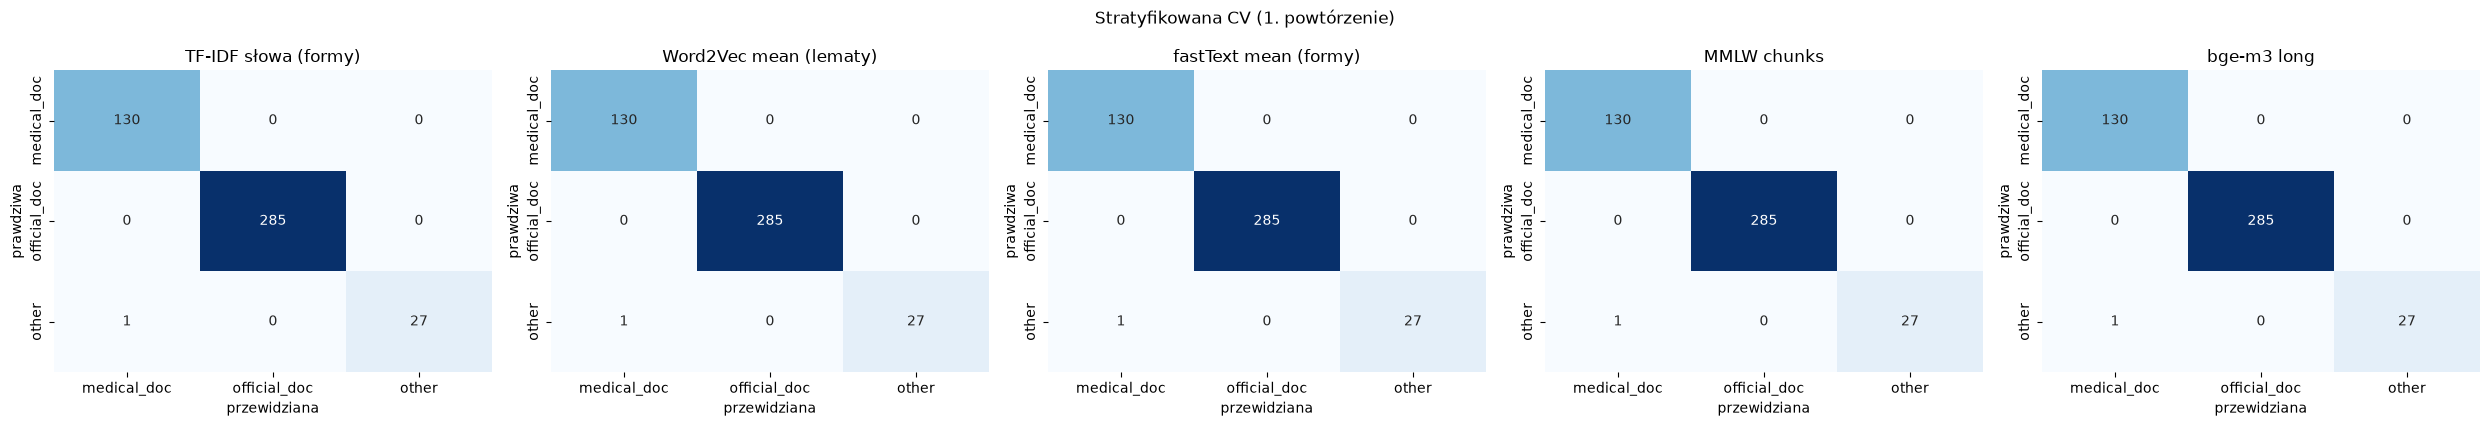

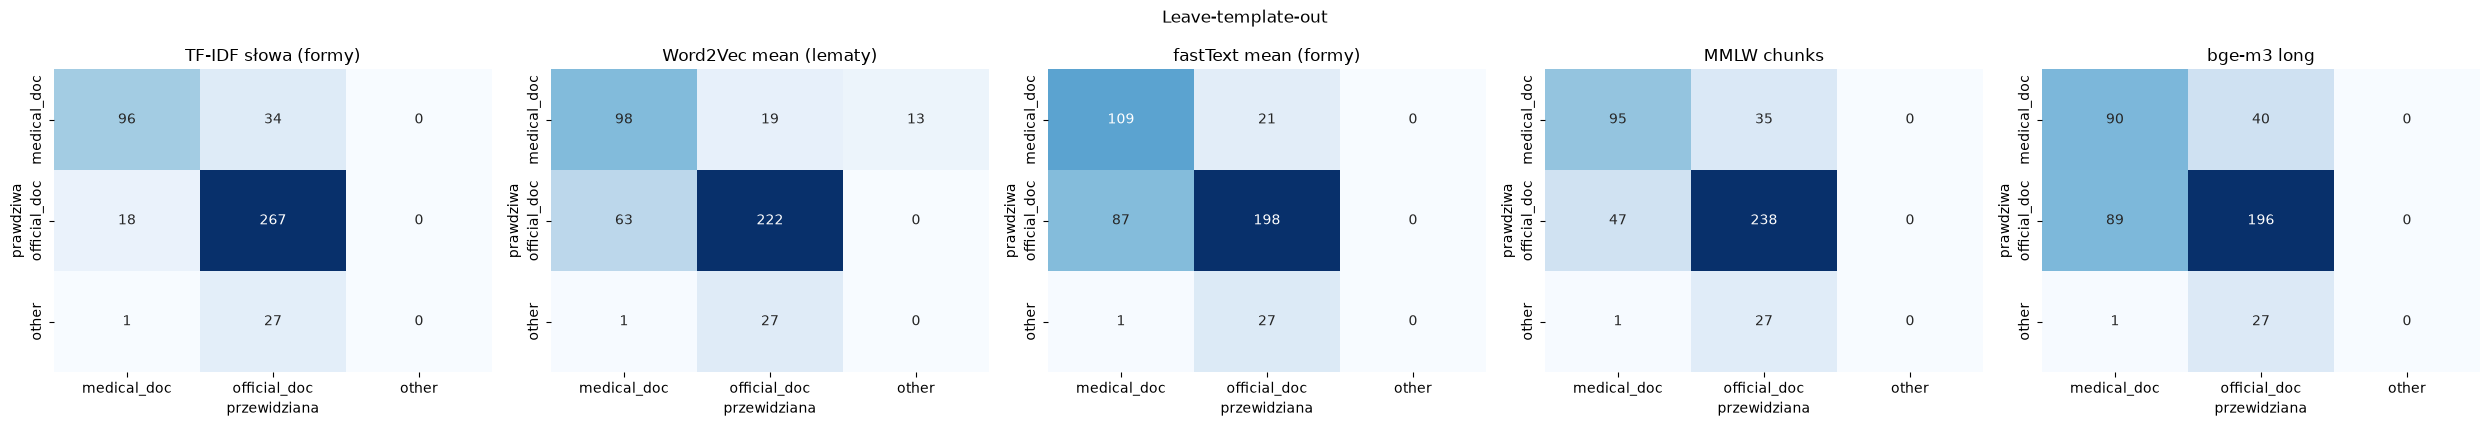

In [15]:
best = {
    "TF-IDF słowa (formy)": ("TF-IDF słowa", "formy"),
    "Word2Vec mean (lematy)": ("Word2Vec mean", "lematy"),
    "fastText mean (formy)": ("fastText mean", "formy"),
    "MMLW chunks": ("MMLW chunks", "formy"),
    "bge-m3 long": ("bge-m3 long", "formy"),
}
for scheme, title in (("stratified", "Stratyfikowana CV (1. powtórzenie)"), ("loto", "Leave-template-out")):
    figure, axes = plt.subplots(1, len(best), figsize=(5 * len(best), 4.3))
    for axis, (name, key) in zip(axes, best.items()):
        probabilities = results[key][scheme]["probabilities"]
        predictions = classify.predictions_from(probabilities[0] if scheme == "stratified" else probabilities)
        matrix = classify.confusion(y, predictions)
        sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis)
        axis.set_title(name)
    figure.suptitle(title)
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / f"confusion_{scheme}.png", dpi=110)
    plt.show()

### 2.3 Analiza błędów a przypadki sporne z Części I

W stratyfikowanej CV dla każdego dokumentu liczymy, w ilu z (17 reprezentacji × 5 powtórzeń) przebiegów został źle sklasyfikowany.

In [16]:
error_counts = np.zeros(len(y))
for key, result in results.items():
    for repeat in result["stratified"]["probabilities"]:
        error_counts += classify.predictions_from(repeat) != y
runs = len(results) * len(next(iter(results.values()))["stratified"]["probabilities"])
errors = corpus.assign(błędy=error_counts.astype(int), udział_błędów=error_counts / runs)
errors = errors[errors["błędy"] > 0].sort_values("błędy", ascending=False)
display(errors[["task_id", "template", "label", "phase", "round", "annotator", "had_disagreement", "błędy", "udział_błędów"]])

disputed = corpus[corpus["had_disagreement"]]
display(Markdown("**Dokumenty sporne z Części I** (Mikołaj vs Szymon w rundzie 1, rozstrzygnięte przez Michała):"))
pilot = pd.read_csv(ROOT / "annotations" / "pilot_annotations.csv")
display(pilot[pilot["task_id"].isin(disputed["task_id"])][["task_id", "annotator", "label", "reason_short", "round"]])

confidence_rows = []
for task_index in disputed.index:
    row = {"task_id": corpus.at[task_index, "task_id"], "etykieta": y[task_index]}
    for name, key in best.items():
        probabilities = results[key]["stratified"]["probabilities"][:, task_index].mean(axis=0)
        row[name] = f"{LABELS[probabilities.argmax()]} ({probabilities.max():.2f})"
    confidence_rows.append(row)
display(Markdown("Przewidywania (średnie prawdopodobieństwo z 5 powtórzeń) dla dokumentów spornych:"))
display(pd.DataFrame(confidence_rows))

,task_id,template,label,phase,round,annotator,had_disagreement,błędy,udział_błędów
54,55,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,other,pilot,1,Mikołaj + Szymon,False,85,1.000000
293,294,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,medical_doc,production,0,Michał,False,1,0.011765
304,305,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,medical_doc,production,0,Szymon,False,1,0.011765


**Dokumenty sporne z Części I** (Mikołaj vs Szymon w rundzie 1, rozstrzygnięte przez Michała):

,task_id,annotator,label,reason_short,round
8,138,Mikołaj,medical_doc,Dokument zawiera informacje o miejscach i historii leczenia pacjenta.,1
16,215,Mikołaj,medical_doc,Dokument zawiera informacje o miejscach i historii leczenia pacjenta.,1
48,138,Szymon,official_doc,Informacja o miejscach leczenia służy pozyskaniu dokumentacji do orzeczenia ZUS.,1
56,215,Szymon,official_doc,Informacja o miejscach leczenia służy pozyskaniu dokumentacji do orzeczenia ZUS.,1


Przewidywania (średnie prawdopodobieństwo z 5 powtórzeń) dla dokumentów spornych:

,task_id,etykieta,TF-IDF słowa (formy),Word2Vec mean (lematy),fastText mean (formy),MMLW chunks,bge-m3 long
0,138,medical_doc,medical_doc (0.47),medical_doc (0.88),medical_doc (0.84),medical_doc (0.90),medical_doc (0.94)
1,215,medical_doc,medical_doc (0.41),medical_doc (0.82),medical_doc (0.69),medical_doc (0.97),medical_doc (0.98)


W leave-template-out sprawdzamy, które szablony są mylone i jakie etykiety dostają zamiast właściwej (najlepsze modele każdej rodziny)?

In [17]:
template_rows = []
for template, members in corpus.groupby("template").groups.items():
    members = np.asarray(list(members))
    row = {"szablon": template, "etykieta": pd.Series(y[members]).mode().iloc[0], "n": len(members)}
    for name, key in best.items():
        predictions = classify.predictions_from(results[key]["loto"]["probabilities"][members])
        row[name] = f"{(predictions == y[members]).mean():.0%}"
    template_rows.append(row)
template_table = pd.DataFrame(template_rows)
display(template_table)

,szablon,etykieta,n,TF-IDF słowa (formy),Word2Vec mean (lematy),fastText mean (formy),MMLW chunks,bge-m3 long
0,T00 zawartej zakładem pieczęć ośrodka ks,medical_doc,18,100%,100%,100%,100%,100%
1,T01 OL-9 ol zaświadczenie stanie zdrowia pieczęć,medical_doc,15,0%,100%,87%,0%,20%
2,T02 zawartej zakładem pieczęć ośrodka ks,medical_doc,10,100%,100%,100%,100%,100%
3,T03 OL-4 ol sprzeciw wobec orzeczenia lekarza,official_doc,18,100%,100%,100%,94%,100%
4,T04 oddział biała podlaska akt opinia,medical_doc,22,100%,100%,100%,95%,59%
5,T05 PR-4 pr wniosek rehabilitację leczniczą ramach,official_doc,28,100%,0%,0%,0%,0%
6,T06 POLTAX poltax pola jasne wypełnia podatnik,official_doc,23,100%,100%,100%,100%,100%
7,T07 zaświadczenie pomocy minimis data wydania,official_doc,3,100%,100%,100%,100%,100%
8,T08 OL-10 ol wywiad zawodowy pieczęć zakładu,official_doc,17,100%,0%,100%,100%,0%
9,T09 OL-2 ol wniosek pracodawcy kontrolę zaświadczenia,official_doc,28,100%,100%,100%,100%,100%


### 2.4 Pyt. 6: prostsze sposoby separacji dokumentów

1. Reguły z wytycznych anotacji: kilka wyrażeń regularnych na nagłówku dokumentu (kody formularzy i tytuły), bez uczenia.
2. Szablon + propagacja etykiety: grupowanie bez nadzoru w szablony, ręczna etykieta jednego losowego dokumentu z każdego szablonu, propagowana na resztę (24 anotacje zamiast 443).
3. Zero-shot: kosinus wektora dokumentu do wektorów opisów klas z wytycznych (bez żadnego treningu).

In [18]:
rule_predictions = np.asarray([classify.rule_based_label(text) for text in corpus["clean_text"]])
display(Markdown(f"**Reguły:** accuracy {np.mean(rule_predictions == y):.3f}, macro-F1 {classify.f1_score(y, rule_predictions, average='macro'):.3f}"))
display(classify.confusion(y, rule_predictions))
display(corpus.loc[rule_predictions != y, ["template", "label"]].assign(reguła=rule_predictions[rule_predictions != y], początek=corpus.loc[rule_predictions != y, "snippet"].str[:90]))

propagation = []
for seed in range(100):
    generator = np.random.default_rng(seed)
    predicted = np.empty(len(y), dtype=object)
    for template, members in corpus.groupby("template_id").groups.items():
        members = np.asarray(list(members))
        predicted[members] = y[generator.choice(members)]
    propagation.append((np.mean(predicted == y), classify.f1_score(y, predicted.astype(str), average="macro")))
propagation = np.asarray(propagation)
display(Markdown(f"**Szablon + 1 etykieta na szablon (100 losowań):** accuracy {propagation[:, 0].mean():.3f} ± {propagation[:, 0].std():.3f}, macro-F1 {propagation[:, 1].mean():.3f}"))

class_descriptions = {
    "medical_doc": "Dokumentacja medyczna pacjenta: stan zdrowia, rozpoznanie, wynik badania, leczenie, rehabilitacja, opinia lekarska, ocena funkcjonowania pacjenta.",
    "official_doc": "Dokument urzędowy: wniosek, deklaracja, zeznanie lub zaświadczenie w sprawie podatkowej, ubezpieczeniowej, pracowniczej, administracyjnej albo kontrolnej.",
    "other": "Inny dokument, który nie jest dokumentacją pacjenta ani dokumentem postępowania urzędowego, np. lista kontrolna, instrukcja lub ankieta warunków pracy.",
}
zero_shot_rows = []
for name, model in encoder_models.items():
    description_vectors = encode_texts(name, list(class_descriptions.values()), model)
    for strategy in ("head", "chunks") + (("long",) if name == "bge-m3" else ()):
        predicted = np.asarray(LABELS)[(normalize(encoded[f"{name}_{strategy}"]) @ description_vectors.T).argmax(axis=1)]
        zero_shot_rows.append(
            {
                "model": f"{name} {strategy}",
                "accuracy": np.mean(predicted == y),
                "macro-F1": classify.f1_score(y, predicted, average="macro"),
            }
        )
w2v = load_static_model(STATIC_MODELS["w2v"])
description_lemmas = [[t.lemma_.lower() for t in doc if t.is_alpha] for doc in nlp.pipe(class_descriptions.values())]
description_vectors = static_document_vectors(w2v, description_lemmas, use_subwords=False)[0]
predicted = np.asarray(LABELS)[(normalize(static["w2v_lemmas_mean"]["vectors"]) @ normalize(description_vectors).T).argmax(axis=1)]
zero_shot_rows.append({"model": "Word2Vec mean (lematy)", "accuracy": np.mean(predicted == y), "macro-F1": classify.f1_score(y, predicted, average="macro")})
del w2v
zero_shot = pd.DataFrame(zero_shot_rows)
display(zero_shot.round(3))

**Reguły:** accuracy 0.995, macro-F1 0.991

przewidziana,medical_doc,official_doc,other
prawdziwa,,,
medical_doc,129,1,0
official_doc,0,285,0
other,1,0,27


,template,label,reguła,początek
54,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,other,medical_doc,Ankieta satysfakcji A. Opieka ambulatoryjna Odpowiedź (X) A1: Czy miała Pani możliwość wyb
293,T13 ankieta satysfakcji opieka ambulatoryjna odpowiedź,medical_doc,official_doc,Ankieta satysfakji A. Opieka ambulatoryjna Odpowiedź (X) A1: Czy miała Pani możliwość wybo


**Szablon + 1 etykieta na szablon (100 losowań):** accuracy 0.995 ± 0.008, macro-F1 0.986

,model,accuracy,macro-F1
0,mmlw head,0.831,0.855
1,mmlw chunks,0.808,0.813
2,bge-m3 head,0.813,0.761
3,bge-m3 chunks,0.813,0.821
4,bge-m3 long,0.844,0.813
5,Word2Vec mean (lematy),0.192,0.226


### 2.5 Dyskusja (pytania pomocnicze)

#### Wyniki ogólne

W stratyfikowanej CV wszystkie 17 reprezentacji osiąga accuracy 0,997-0,998 i macro-F1 0,989-0,992.
Jedyny stały błąd to dokument 55 (ankieta z etykietą `other`), mylony we wszystkich 85 przebiegach. Dwie inne ankiety zostały źle sklasyfikowane po jednym razie.
Według wytycznych v2 klasyfikator ma przy dokumencie 55 rację.
Stratyfikowana CV mierzy tu jednak głównie rozpoznawanie znanego formularza.

W leave-template-out najlepsze są TF-IDF na formach (accuracy 0,819, F1 dla `medical_doc` i `official_doc` 0,827) oraz Word2Vec SIF na formach (0,819 / 0,828). Enkodery osiągają 0,585-0,752.
Macro-F1 dla 3 klas jest ograniczone przez `other`, którego nie da się nauczyć po wyłączeniu jedynego szablonu tej klasy.
Wyjątkiem jest bge-m3 head (macro-F1 0,795): poprawnie rozpoznał wszystkie 27 dokumentów `other` z niewidzianego szablonu, choć w zbiorze treningowym był tylko jeden przykład `other`, czyli błędnie oznaczona ankieta.
Oba dokumenty to kwestionariusze z pytaniami „Czy...?” i odpowiedziami Tak/Nie, więc model nauczył się, że `other` to ankieta. To przypadek, a nie zasługa modelu.
Uwaga o wariancji: grup jest 24, więc pomyłka na jednym szablonie zmienia accuracy o 3-7 pp. Różnic mniejszych niż ~0,05 nie należy interpretować.

#### Pyt. 1. Lematyzacja a słownik i TF-IDF

Lematyzacja zmniejsza słownik z 5399 do 4514 typów (-16,4%), a po odcięciu `min_df=2` z 4191 do 3266 (-22%).
Przykładowo lemat „prowadzić” zbiera 13 różnych form, a „być” i „wykonywać” po 12.
W stratyfikowanej CV wynik się nie zmienia (sufit 0,992). W leave-template-out lematy dają nieznacznie gorszy wynik (0,808 wobec 0,827), co mieści się w szumie.
W polskim efekt powinien być silniejszy niż w angielskim, bo rzeczownik ma do 14 form (7 przypadków × 2 liczby), a czasownik kilkadziesiąt. Bez lematyzacji jedno słowo rozbija się na wiele rzadkich cech.
Tu efekt jest mały, bo dokumenty powstały z szablonów: te same frazy pojawiają się w tych samych formach, więc forma niesie tę samą informację co lemat.

#### Pyt. 2. Lematyzacja a modele statyczne. Czy fastText jest mniej wrażliwy?

Word2Vec KGR10 był trenowany na lematach (pkt 2c), co widać w pokryciu słownika: 72,5% dla form i 93,9% dla lematów.
Lepsze pokrycie nie przełożyło się jednak na wynik. Dla średniej leave-template-out daje 0,736 na formach i 0,737 na lematach, a dla SIF 0,828 na formach i 0,745 na lematach.
Przy formach wektor powstaje głównie z form, które są jednocześnie lematem (rzeczowniki w mianowniku, bezokoliczniki, tytuły formularzy). Pozostałe słowa są pomijane jak stop-words, a to akurat pomaga w tym zbiorze.
fastText (trenowany na formach) jest mniej wrażliwy: pokrycie 99,5% wobec 97,6%, a wyniki 0,706 wobec 0,680 (średnia) i 0,706 wobec 0,701 (SIF).
n-gramy znakowe sprawiają, że formy jednego słowa i tak mają podobne wektory (wspólny rdzeń), więc lematyzacja niewiele zmienia.

#### Pyt. 3. Dlaczego nie lematyzuje się tekstu dla enkoderów transformerowych?

Enkoder dzieli tekst na podsłowa i wykorzystuje kontekst, więc sam radzi sobie z fleksją. Uczono go na naturalnym tekście.
Lematyzacja usuwa informację gramatyczną (przypadek, liczbę, czas, aspekt) i tworzy nienaturalne ciągi słów, które są dla modelu danymi spoza rozkładu treningowego.
Eksperyment kontrolny to potwierdza: MMLW na tekście zlematyzowanym spada w leave-template-out z 0,755 do 0,728, a w stratyfikowanej CV nic nie zyskuje.

#### Pyt. 4. Czy TF-IDF jest konkurencyjny wobec enkodera zdań?

Tak, a w leave-template-out jest nawet lepszy: 0,819 wobec 0,752 dla najlepszego enkodera (MMLW chunks). W stratyfikowanej CV wyniki są równe.
Wynika to z natury danych: klasę wyznaczają słowa kluczowe dziedziny.
Regresja logistyczna na TF-IDF sama wybiera słowa dyskryminujące i ignoruje resztę. Enkoder bez dostrajania kompresuje cały tekst (dane osobowe, instrukcje, klauzulę RODO) do jednego wektora i nie wie, co jest istotne dla zadania.
Enkodery wygrywają tam, gdzie nie ma danych treningowych: zero-shot daje 0,81-0,84 accuracy bez żadnego przykładu.
Opisy klas pochodzą z wytycznych, więc wynik zależy od ich sformułowania.

#### Pyt. 5. Czy błędy klasyfikatora pokrywają się z przypadkami spornymi?

W stratyfikowanej CV nie. Oba dokumenty sporne (138 i 215, OL-9A) są klasyfikowane poprawnie przez wszystkie modele, z prawdopodobieństwem 0,69-0,98. Tylko TF-IDF jest wyraźnie mniej pewny (0,41-0,47).
Jedyny stały błąd to dokument 55, przy którym anotatorzy byli zgodni, ale stosowali wytyczne v1. Klasyfikator wskazał więc niespójność etykiet, której miara zgodności nie wykryła.

W leave-template-out odpowiedź brzmi tak. Wszystkie modele mylą dwa szablony:
* OL-9A (T10, `medical_doc` przewidywane jako `official_doc`),
* kontrolę organizacji świadczeń w placówce (T11, `official_doc` przewidywane jako `medical_doc`).
To dokładnie przypadki graniczne, dla których po iteracji 1 dopisano reguły do wytycznych v2.
Ich etykieta wynika z przyjętej konwencji, a nie z samej treści, więc model, który nie widział danego formularza, nie może jej odtworzyć.

#### Pyt. 6. Czy jest prostszy sposób separacji dokumentów?

Tak. Kilka wyrażeń regularnych na nagłówku dokumentu, przepisanych z wytycznych v2, daje accuracy 0,995 i macro-F1 0,991 bez żadnego uczenia.
Oba błędy to ankiety: dokument 55 z szumem w etykiecie i ankieta z błędem OCR w tytule („satysfakji”), co pokazuje kruchość reguł.
Równie dobrze działa grupowanie dokumentów w szablony bez nadzoru i ręczne oznaczenie jednego dokumentu z każdego szablonu: 0,995 ± 0,008 przy 24 etykietach zamiast 443.
HDBSCAN na dowolnych osadzeniach odtwarza szablony (ARI 0,89-0,97).
Zbiór jest więc wygenerowany z około 24 formularzy, a klasyfikacja sprowadza się do rozpoznania formularza.

#### Pyt. 7. Dokumenty pisane odręcznie zostały pominięte.

#### Podsumowanie

Zebrane dane pozwalają automatycznie rozpoznawać etykiety znanych formularzy niemal bezbłędnie (accuracy ~0,998).
Dla nowych formularzy dokładność spada do 0,75-0,82, a klasa `other` jest reprezentowana przez jeden szablon, czego nie wystarcza do nauczenia jej ogólnej definicji.
Aby ocenić rozumienie treści, a nie rozpoznawanie formularza, zbiór potrzebuje większej różnorodności szablonów, zwłaszcza w klasie `other`.